Page outline

1. Read the dataset with pd.read_csv(...).

2. Inspect the data with print(df) and df.info().

3. Clean column names by stripping extra spaces.

4. Convert text values to numbers/dates by removing $, -, and ,, then using numeric conversion and pd.to_datetime().

5. Check duplicates with df.duplicated() and remove them with df.drop_duplicates().

6. Check missing values with df.isna().sum().

7. Handle missing data either by dropping rows with df.dropna() or by imputation.

8. Create a copy with df3 = df.copy().

9. Fill missing numeric fields using grouped means for Units Sold, Sale Price, and Gross Sales.

10. Fill missing Discounts and Profit with 0.

11. Print the cleaned dataframe with print(df3)

In [27]:
##STEP 1:Basics of all tasks
import pandas as pd #library to see data
import numpy as np #library to use numerical functions

pd.set_option('display.expand_frame_repr', False) #to display all columns in the dataframe without truncating/rapping it in many lines
df = pd.read_csv('Financials4.csv') #just to read or load, no view of the data yet
print(df.head()) #see the first 5 rows of the dataframe



   Unnamed: 0     Segment  Country     Product   Discount Band   Units Sold   Manufacturing Price   Sale Price   Gross Sales   Discounts        Sales         COGS       Profit       Date  Month Number  Month Name   Year
0           0  Government   Canada   Carretera            None    $1,618.50                 $3.00           NaN   $32,370.00        $-     $32,370.00   $16,185.00   $16,185.00   1/1/2014             1     January   2014
1           1  Government  Germany   Carretera            None    $1,321.00                 $3.00       $20.00    $26,420.00        $-     $26,420.00   $13,210.00   $13,210.00   1/1/2014             1     January   2014
2           2   Midmarket   France   Carretera            None    $2,178.00                 $3.00       $15.00    $32,670.00        $-     $32,670.00   $21,780.00   $10,890.00   1/6/2014             6        June   2014
3           3   Midmarket  Germany   Carretera            None           NaN                $3.00       $15.00    $13,32

In [28]:

print(df.shape) #see the number of rows and columns in the dataframe


(701, 17)


In [29]:
print(df.info()) #see the data types of each column and if there are any missing values


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 701 entries, 0 to 700
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Unnamed: 0             701 non-null    int64 
 1   Segment                701 non-null    object
 2   Country                701 non-null    object
 3    Product               701 non-null    object
 4    Discount Band         701 non-null    object
 5    Units Sold            700 non-null    object
 6    Manufacturing Price   701 non-null    object
 7    Sale Price            700 non-null    object
 8    Gross Sales           699 non-null    object
 9    Discounts             701 non-null    object
 10    Sales                701 non-null    object
 11   COGS                  701 non-null    object
 12   Profit                701 non-null    object
 13  Date                   701 non-null    object
 14  Month Number           701 non-null    int64 
 15   Month Name            

In [30]:
print(df.columns) #see the column names in the dataframe


Index(['Unnamed: 0', 'Segment', 'Country', ' Product ', ' Discount Band ',
       ' Units Sold ', ' Manufacturing Price ', ' Sale Price ',
       ' Gross Sales ', ' Discounts ', '  Sales ', ' COGS ', ' Profit ',
       'Date', 'Month Number', ' Month Name ', 'Year'],
      dtype='object')


In [31]:
print(df.isna().sum()) #see the number of missing values in each column

Unnamed: 0               0
Segment                  0
Country                  0
 Product                 0
 Discount Band           0
 Units Sold              1
 Manufacturing Price     0
 Sale Price              1
 Gross Sales             2
 Discounts               0
  Sales                  0
 COGS                    0
 Profit                  0
Date                     0
Month Number             0
 Month Name              0
Year                     0
dtype: int64


In [32]:
print(df)

     Unnamed: 0           Segment                   Country     Product   Discount Band   Units Sold   Manufacturing Price   Sale Price     Gross Sales    Discounts           Sales            COGS       Profit        Date  Month Number  Month Name   Year
0             0        Government                    Canada   Carretera            None    $1,618.50                 $3.00           NaN     $32,370.00         $-        $32,370.00      $16,185.00   $16,185.00    1/1/2014             1     January   2014
1             1        Government                   Germany   Carretera            None    $1,321.00                 $3.00       $20.00      $26,420.00         $-        $26,420.00      $13,210.00   $13,210.00    1/1/2014             1     January   2014
2             2         Midmarket                    France   Carretera            None    $2,178.00                 $3.00       $15.00      $32,670.00         $-        $32,670.00      $21,780.00   $10,890.00    1/6/2014             6

So, AFTER STEP 1,  we see first coloum is unnecessary and extra, Left-most number in the printout is the row index. The first column seems extra so we remove it immediately.

In [33]:
## STEP 2: Data Cleaning

df = df.drop(columns=['Unnamed: 0'])

This comes as already droped the colum called 'unnamed: 0'

In [34]:
df #to see updated dataframe after dropping the column

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Canada,Carretera,None,"$1,618.50",$3.00,NaN,"$32,370.00",$-,"$32,370.00","$16,185.00","$16,185.00",1/1/2014,1,January,2014
1,Government,Germany,Carretera,None,"$1,321.00",$3.00,$20.00,"$26,420.00",$-,"$26,420.00","$13,210.00","$13,210.00",1/1/2014,1,January,2014
2,Midmarket,France,Carretera,None,"$2,178.00",$3.00,$15.00,"$32,670.00",$-,"$32,670.00","$21,780.00","$10,890.00",1/6/2014,6,June,2014
3,Midmarket,Germany,Carretera,None,NaN,$3.00,$15.00,"$13,320.00",$-,"$13,320.00","$8,880.00","$4,440.00",1/6/2014,6,June,2014
4,Midmarket,Mexico,Carretera,None,"$2,470.00",$3.00,"$1,000,000","$37,050.00",$-,"$37,050.00","$24,700.00","$12,350.00",1/6/2014,6,June,2014
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
696,Small Business,Mexico,Amarilla,High,$546.00,$260.00,$300.00,"$1,63,800.00","$24,570.00","$1,39,230.00","$1,36,500.00","$2,730.00",1/10/2014,10,October,2014
697,Government,Mexico,Montana,High,"$1,368.00",$5.00,$7.00,"$9,576.00","$1,436.40","$8,139.60","$6,840.00","$1,299.60",1/2/2014,2,February,2014
698,Government,Canada,Paseo,High,$723.00,$10.00,$7.00,"$5,061.00",$759.15,"$4,301.85","$3,615.00",$686.85,1/4/2014,4,April,2014
699,Channel Partners,United States of America,VTT,High,"$1,806.00",$250.00,$12.00,NaN,"$3,250.80","$18,421.20","$5,418.00","$13,003.20",1/5/2014,5,May,2014


In [35]:
df.info() # summary and data types of the dataframe after dropping the column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 701 entries, 0 to 700
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Segment                701 non-null    object
 1   Country                701 non-null    object
 2    Product               701 non-null    object
 3    Discount Band         701 non-null    object
 4    Units Sold            700 non-null    object
 5    Manufacturing Price   701 non-null    object
 6    Sale Price            700 non-null    object
 7    Gross Sales           699 non-null    object
 8    Discounts             701 non-null    object
 9     Sales                701 non-null    object
 10   COGS                  701 non-null    object
 11   Profit                701 non-null    object
 12  Date                   701 non-null    object
 13  Month Number           701 non-null    int64 
 14   Month Name            701 non-null    object
 15  Year                   

Here, some colum have missing value, like unit sold has 1 missing value and "object" means string type while int64 are integer types. Moreover, some column names contain whitespace as we see from

In [36]:
df.columns # see the column names

Index(['Segment', 'Country', ' Product ', ' Discount Band ', ' Units Sold ',
       ' Manufacturing Price ', ' Sale Price ', ' Gross Sales ', ' Discounts ',
       '  Sales ', ' COGS ', ' Profit ', 'Date', 'Month Number',
       ' Month Name ', 'Year'],
      dtype='object')

In [37]:
df.columns = df.columns.str.strip() #removes extra whitespace (spaces) from all column names
df.columns # see the updated column names after stripping whitespace

Index(['Segment', 'Country', 'Product', 'Discount Band', 'Units Sold',
       'Manufacturing Price', 'Sale Price', 'Gross Sales', 'Discounts',
       'Sales', 'COGS', 'Profit', 'Date', 'Month Number', 'Month Name',
       'Year'],
      dtype='object')

In [38]:
#make colum as its data type-
#  loops to read columns which contain numerical values only, but defined as strings (object)
for col in ['Units Sold',
       'Manufacturing Price', 'Sale Price', 'Gross Sales', 'Discounts',
       'Sales', 'COGS', 'Profit']:
    if df[col].dtype == 'object': #cheking data type- object, where should be text or strings not numbers
        df[col] = df[col].str.replace('$', '').str.replace(',', '').str.replace('-', '').str.strip() #removing $,coma, -, any extra spaces
        df[col] = df[col].replace('', np.nan).astype(float)
        
#Date" column from text into real datetime values so Python can treat them as dates instead of plain strings.
df['Date'] = pd.to_datetime(df['Date'])

print(df)

              Segment                   Country      Product Discount Band  Units Sold  Manufacturing Price  Sale Price  Gross Sales  Discounts      Sales      COGS    Profit       Date  Month Number  Month Name  Year
0          Government                    Canada   Carretera          None       1618.5                  3.0         NaN      32370.0        NaN   32370.00   16185.0  16185.00 2014-01-01             1    January   2014
1          Government                   Germany   Carretera          None       1321.0                  3.0        20.0      26420.0        NaN   26420.00   13210.0  13210.00 2014-01-01             1    January   2014
2           Midmarket                    France   Carretera          None       2178.0                  3.0        15.0      32670.0        NaN   32670.00   21780.0  10890.00 2014-01-06             6       June   2014
3           Midmarket                   Germany   Carretera          None          NaN                  3.0        15.0      133

In [39]:
#Next we check if there are any duplicated rows (records).
print(df.index[df.duplicated(keep=False)])

Index([699, 700], dtype='int64')


The last two rows are exactly the same so drop one of them.

In [40]:
df = df.drop_duplicates() #dropping duplicates
print(df)

              Segment                   Country      Product Discount Band  Units Sold  Manufacturing Price  Sale Price  Gross Sales  Discounts      Sales      COGS    Profit       Date  Month Number  Month Name  Year
0          Government                    Canada   Carretera          None       1618.5                  3.0         NaN      32370.0        NaN   32370.00   16185.0  16185.00 2014-01-01             1    January   2014
1          Government                   Germany   Carretera          None       1321.0                  3.0        20.0      26420.0        NaN   26420.00   13210.0  13210.00 2014-01-01             1    January   2014
2           Midmarket                    France   Carretera          None       2178.0                  3.0        15.0      32670.0        NaN   32670.00   21780.0  10890.00 2014-01-06             6       June   2014
3           Midmarket                   Germany   Carretera          None          NaN                  3.0        15.0      133

In [41]:
#Moving on to check missing values by column we have the following output.
print(df.isna().sum())

Segment                 0
Country                 0
Product                 0
Discount Band           0
Units Sold              1
Manufacturing Price     0
Sale Price              1
Gross Sales             1
Discounts              53
Sales                   0
COGS                    0
Profit                  5
Date                    0
Month Number            0
Month Name              0
Year                    0
dtype: int64


In [42]:
#df2 = df.dropna() removes every row that has at least one missing value in any column of the dataframe.
df2 = df.dropna()
print(df2)

            Segment Country     Product Discount Band  Units Sold  Manufacturing Price  Sale Price  Gross Sales  Discounts      Sales      COGS    Profit       Date  Month Number  Month Name  Year
53       Government  France      Paseo           Low       3945.0                 10.0         7.0      27615.0     276.15   27338.85   19725.0   7613.85 2014-01-01             1    January   2014
54        Midmarket  France      Paseo           Low       2296.0                 10.0        15.0      34440.0     344.40   34095.60   22960.0  11135.60 2014-01-02             2   February   2014
55       Government  France      Paseo           Low       1030.0                 10.0         7.0       7210.0      72.10    7137.90    5150.0   1987.90 2014-01-05             5        May   2014
56       Government  France       Velo           Low        639.0                120.0         7.0       4473.0      44.73    4428.27    3195.0   1233.27 2014-01-11            11   November   2014
57       Govern

In [43]:
#to check after dropping missing values
print(df2.isna().sum())

Segment                0
Country                0
Product                0
Discount Band          0
Units Sold             0
Manufacturing Price    0
Sale Price             0
Gross Sales            0
Discounts              0
Sales                  0
COGS                   0
Profit                 0
Date                   0
Month Number           0
Month Name             0
Year                   0
dtype: int64


In [44]:
#imputation (filling in missing values instead of deleting the whole row); adding a mean in the missing values columns, not just adding zeros! because you are saying “the missing value should be 0,” while the group-mean method is saying “estimate the missing value from similar rows.”

df3 = df.copy() #makes a new copy so the original data stays unchanged.

#df3['Units Sold'] = ...fillna(...) fills missing Units Sold values with the group mean for that same Segment, Country, and Product.
df3['Units Sold'] = df3['Units Sold'].fillna(df3.groupby(['Segment', 'Country', 'Product'])['Units Sold'].transform('mean'))

#simerlarly
df3['Sale Price'] = df3['Sale Price'].fillna(df3.groupby(['Segment', 'Country', 'Product'])['Sale Price'].transform('mean'))
df3['Gross Sales'] = df3['Gross Sales'].fillna(df3.groupby(['Segment', 'Country', 'Product'])['Gross Sales'].transform('mean'))

#discount and profit can be oly zeros
df3['Discounts'] = df3['Discounts'].fillna(0) #replaces missing discounts with zero.
df3['Profit'] =df3['Profit'].fillna(0) #replaces missing profit with zero.

print(df3)

              Segment                   Country      Product Discount Band  Units Sold  Manufacturing Price  Sale Price  Gross Sales  Discounts      Sales      COGS    Profit       Date  Month Number  Month Name  Year
0          Government                    Canada   Carretera          None       1618.5                  3.0       146.8      32370.0       0.00   32370.00   16185.0  16185.00 2014-01-01             1    January   2014
1          Government                   Germany   Carretera          None       1321.0                  3.0        20.0      26420.0       0.00   26420.00   13210.0  13210.00 2014-01-01             1    January   2014
2           Midmarket                    France   Carretera          None       2178.0                  3.0        15.0      32670.0       0.00   32670.00   21780.0  10890.00 2014-01-06             6       June   2014
3           Midmarket                   Germany   Carretera          None       1513.0                  3.0        15.0      133

In [45]:
df3.describe()

,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Year
count,700.000000,700.000000,700.000000,7.000000e+02,700.000000,7.000000e+02,700.000000,700.000000,700,700.000000,700.000000
mean,1609.187143,96.477143,1547.159714,1.827620e+05,13150.354671,1.696091e+05,145475.211429,26354.778271,2013-10-08 15:36:00,7.900000,2013.750000
min,200.000000,3.000000,7.000000,1.799000e+03,0.000000,1.655080e+03,918.000000,0.000000,2013-01-09 00:00:00,1.000000,2013.000000
25%,907.250000,5.000000,12.000000,1.739175e+04,800.320000,1.592800e+04,7490.000000,3815.707500,2013-10-04 12:00:00,5.750000,2013.750000
50%,1542.500000,10.000000,20.000000,3.798000e+04,2585.250000,3.554020e+04,22506.250000,11110.550000,2014-01-05 12:00:00,9.000000,2014.000000
75%,2229.125000,250.000000,300.000000,2.790250e+05,15956.347500,2.610775e+05,245607.500000,23756.360000,2014-01-09 06:00:00,10.250000,2014.000000
max,4492.500000,260.000000,1000000.000000,1.207500e+06,149677.500000,1.159200e+06,950625.000000,262200.000000,2014-01-12 00:00:00,12.000000,2014.000000
std,867.006947,108.602612,37792.205807,2.542607e+05,22962.928760,2.367263e+05,203865.506118,41426.798657,NaN,3.377321,0.433322


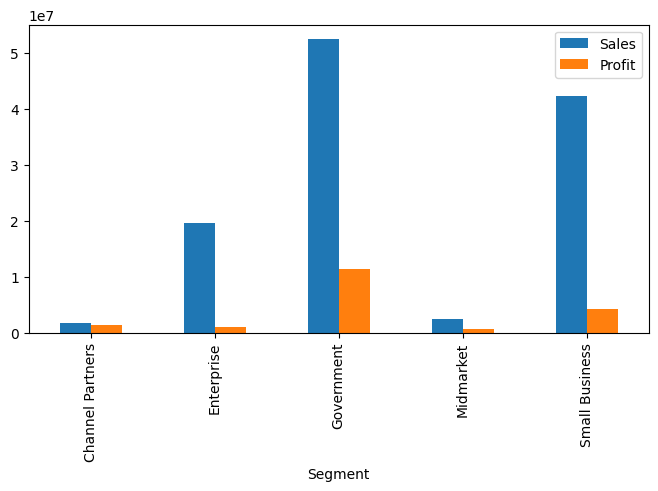

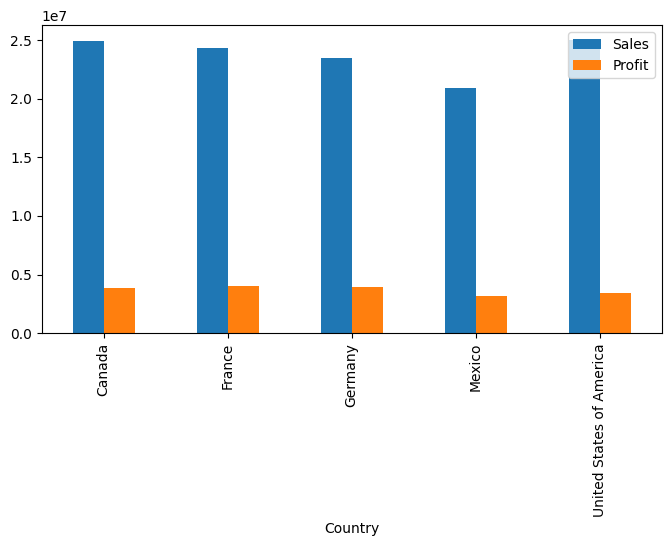

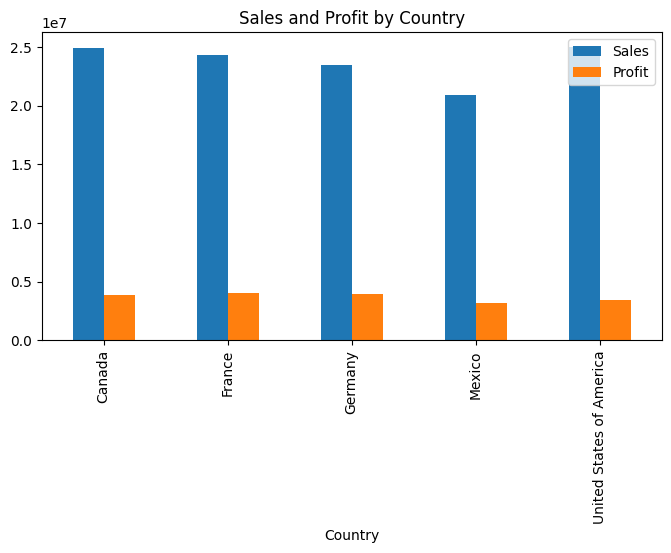

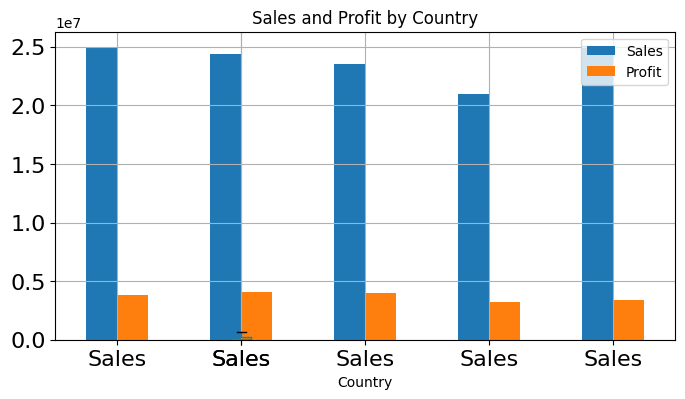

In [46]:
#easier interpretation we may use the box plot 
import matplotlib.pyplot as plt
ax = df3.boxplot(column=['Sales'],showfliers=False)
ax.tick_params(axis='both', labelsize=16)
plt.show()

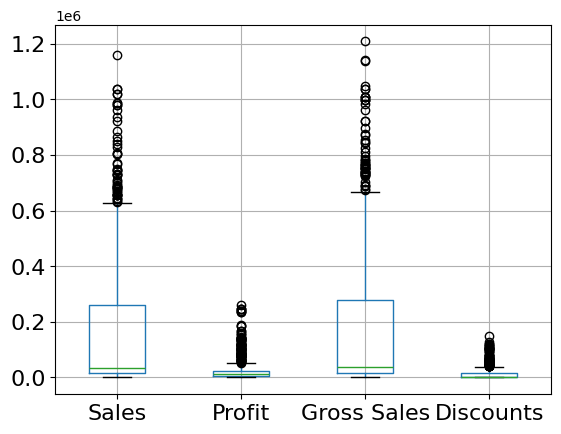

In [47]:
ax = df3.boxplot(column=['Sales','Profit', 'Gross Sales', 'Discounts'])
ax.tick_params(axis='both', labelsize=16)
plt.show()

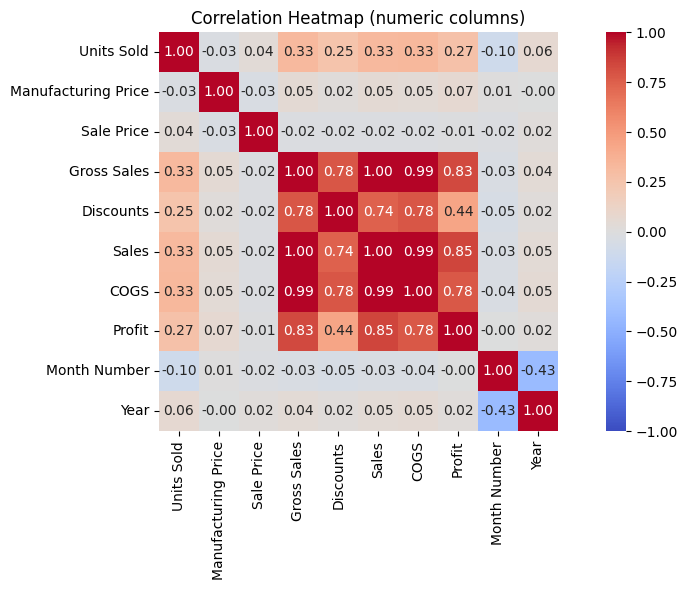

In [48]:
#correlations between columns using a heatmap
corr = df3.select_dtypes(include=np.number).corr()  #creates a correlation matrix where every numeric column is compared with every other numeric column

import seaborn as sns                               #Seaborn draws it as a heatmap
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation Heatmap (numeric columns)")
plt.tight_layout()
plt.show()

In [49]:
#produces a new summarized DataFrame.
agg = df3.groupby('Segment').agg({'Sales': 'sum', 'Profit': 'sum'})
agg.plot(kind="bar", figsize=(8, 4))
print(agg)

                        Sales       Profit
Segment                                   
Channel Partners   1800593.64   1316803.14
Enterprise        19611694.38    940096.88
Government        52504260.68  11388173.18
Midmarket          2381883.09    660103.09
Small Business    42427918.50   4143168.50


In [50]:
#also can grouped by country
agg2 = df3.groupby('Country').agg({'Sales': 'sum', 'Profit': 'sum'})
agg2.plot(kind="bar", figsize=(8, 4))
print(agg2)

                                Sales      Profit
Country                                          
Canada                    24887654.89  3858206.39
France                    24354172.29  4032488.29
Germany                   23505340.82  3961381.32
Mexico                    20949352.11  3198923.11
United States of America  25029830.18  3397345.68


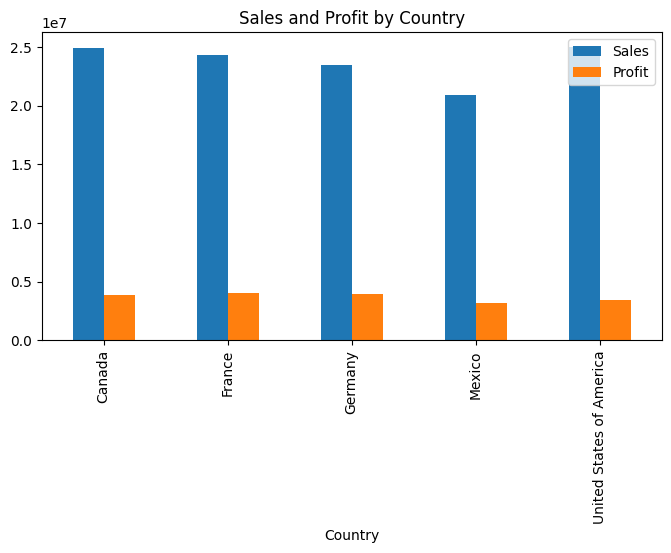

In [54]:

import matplotlib.pyplot as plt
ax = agg2.plot(kind="bar", figsize=(8, 4))
ax.set_title("Sales and Profit by Country")
plt.show()
